# 05 — YOLO Fish Detection

Fine-tunes Ultralytics YOLO on the dataset `04_dataset_preparation.ipynb` built. Uses `yolo11n.pt` as the base checkpoint, matching the weights already referenced in `configs/default.yaml` for the C++ app's pipeline — this notebook produces a drop-in replacement for that weights file, not a different model family.

**Scope check**: `EPOCHS=15` is a matched-budget benchmark run, shared with `05b_rtdetr_fish_detection.ipynb` and `05c_faster_rcnn_fish_detection.ipynb` so the three-way comparison in `05d_detector_comparison.ipynb` compares architectures on equal training budget, not "one model got 10x the epochs." It is still not a claim of full convergence for any of the three -- see `05d`'s discussion cell before treating this as a final answer.

**Kernel:** **AquaTrack+ (.venv)**.

## Configuration

In [1]:
# --- Edit for your run, then Run All ------------------------------------
DATASET_YAML = r"C:\Users\oyele\AquaTrack_data\sfishtrack_yolo\dataset.yaml"
MODEL_WEIGHTS = "yolo11n.pt"  # matches configs/default.yaml's model.weights
EPOCHS = 15         # matched-budget benchmark run -- see notebook intro
PATIENCE = 10       # stop early if val mAP hasn't improved in this many epochs
IMAGE_SIZE = 640
BATCH_SIZE = 16
DEVICE = 0          # GPU index (this machine's RTX 5070 Ti); "cpu" to force CPU
RUN_NAME = "sfishtrack_15ep"
METRICS_DIR = r"D:\Software_and_Web\softwares\AquaTrack+\runs\fish_detector_benchmark\metrics"
PILOT = False
# ------------------------------------------------------------------------

In [2]:
from pathlib import Path

dataset_yaml = Path(DATASET_YAML)
assert dataset_yaml.is_file(), (
    f"DATASET_YAML not found: {dataset_yaml} -- run 04_dataset_preparation.ipynb first"
)
print(f"Training against {dataset_yaml}")

Training against C:\Users\oyele\AquaTrack_data\sfishtrack_yolo\dataset.yaml


## Confirm GPU before spending any training time on CPU by accident

In [3]:
import torch

assert torch.cuda.is_available(), (
    "CUDA not available -- check 00_environment_check.ipynb before training. "
    "Training will still run on CPU if you set DEVICE='cpu' deliberately, "
    "but that's a very different time budget."
)
print("GPU:", torch.cuda.get_device_name(0))

GPU: NVIDIA GeForce RTX 5070 Ti


## Train

In [4]:
from ultralytics import YOLO

model = YOLO(MODEL_WEIGHTS)
results = model.train(
    data=str(dataset_yaml),
    epochs=EPOCHS,
    patience=PATIENCE,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    name=RUN_NAME,
    exist_ok=True,
)

Ultralytics 8.4.137  Python-3.13.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16303MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\oyele\AquaTrack_data\sfishtrack_yolo\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=sfishtrack_15ep, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (17,609 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 123/123 4.7it/s 26.1s

                   all       3922      23748      0.419      0.447      0.307      0.136


Speed: 0.1ms preprocess, 1.8ms inference, 0.0ms loss, 1.3ms postprocess per image


Results saved to D:\Software_and_Web\softwares\AquaTrack+\runs\detect\sfishtrack_15ep


## Training curves

Ultralytics writes `results.csv` and `results.png` into the run directory automatically — read the CSV back for the numbers, not just the eyeballed PNG.

In [5]:
import pandas as pd

run_dir = Path(model.trainer.save_dir)
print("run directory:", run_dir)
results_csv = pd.read_csv(run_dir / "results.csv")
results_csv.columns = [c.strip() for c in results_csv.columns]
results_csv[["epoch", "train/box_loss", "train/cls_loss", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]]

run directory: D:\Software_and_Web\softwares\AquaTrack+\runs\detect\sfishtrack_15ep


,epoch,train/box_loss,train/cls_loss,metrics/mAP50(B),metrics/mAP50-95(B)
0,1,2.21495,1.96588,0.25318,0.10930
1,2,2.12530,1.58202,0.21241,0.07607
2,3,2.07727,1.50016,0.30629,0.13543
3,4,2.01373,1.42827,0.27616,0.11450
4,5,1.95185,1.35647,0.29863,0.13163
5,6,1.85098,1.29913,0.23460,0.07746
6,7,1.80294,1.24119,0.25990,0.10649
7,8,1.76106,1.19748,0.27996,0.10984
8,9,1.72857,1.16010,0.20152,0.06887
9,10,1.69105,1.11891,0.24883,0.09493


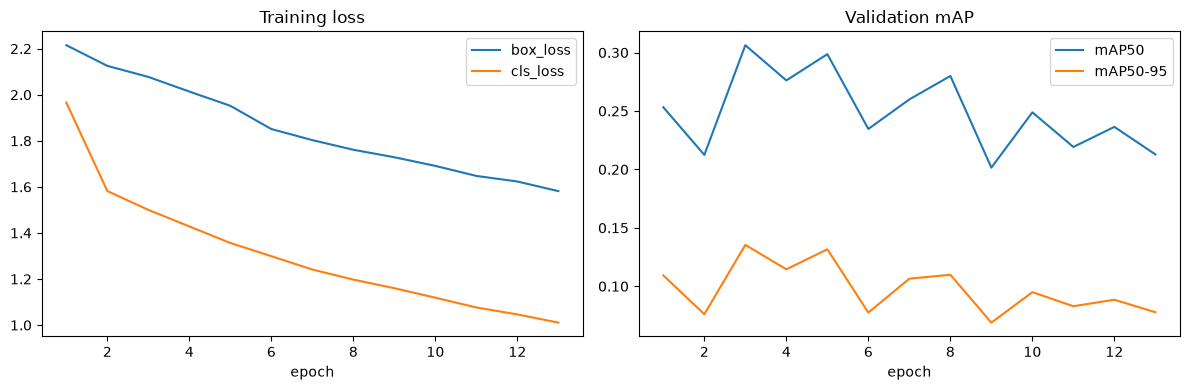

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(results_csv["epoch"], results_csv["train/box_loss"], label="box_loss")
axes[0].plot(results_csv["epoch"], results_csv["train/cls_loss"], label="cls_loss")
axes[0].set_xlabel("epoch"); axes[0].set_title("Training loss"); axes[0].legend()
axes[1].plot(results_csv["epoch"], results_csv["metrics/mAP50(B)"], label="mAP50")
axes[1].plot(results_csv["epoch"], results_csv["metrics/mAP50-95(B)"], label="mAP50-95")
axes[1].set_xlabel("epoch"); axes[1].set_title("Validation mAP"); axes[1].legend()
plt.tight_layout()
plt.show()

## Sanity check: loss should have gone down

Not a claim of a good model at 3 epochs -- a claim that the pipeline (data loading, augmentation, GPU forward/backward pass) is actually learning something rather than silently no-op-ing.

In [7]:
first_loss = results_csv["train/box_loss"].iloc[0]
last_loss = results_csv["train/box_loss"].iloc[-1]
print(f"box_loss: {first_loss:.4f} -> {last_loss:.4f}")
assert last_loss < first_loss, (
    "Loss did not decrease -- something is wrong with the data or training "
    "setup, investigate before trusting this pipeline for a real run."
)
print("Loss decreased -- the training pipeline is genuinely learning.")

box_loss: 2.2149 -> 1.5816
Loss decreased -- the training pipeline is genuinely learning.


## Inference on a real validation image

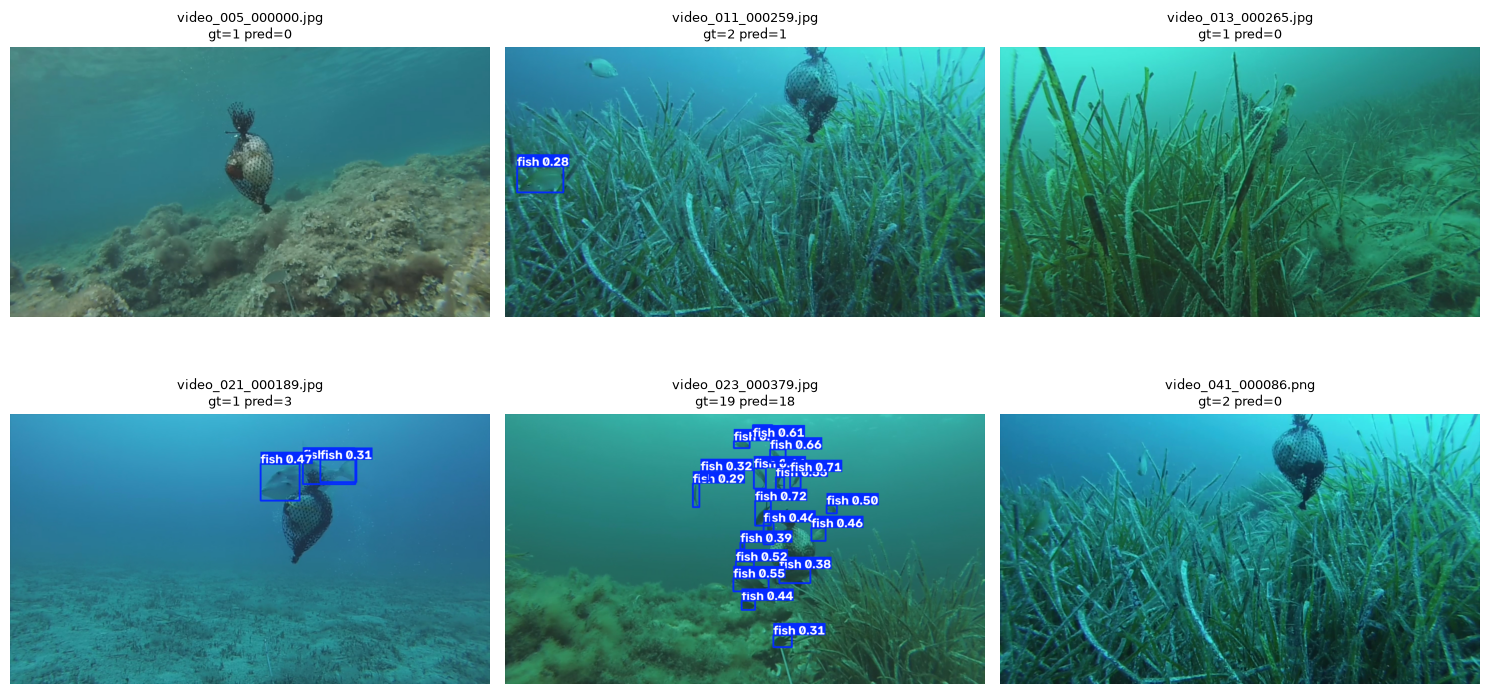

In [8]:
import cv2

best_weights = run_dir / "weights" / "best.pt"
inference_model = YOLO(str(best_weights))

# Several images spread across the val set, not just the first alphabetically --
# a single sample can misleadingly show 0 detections even when the model works,
# purely because that one frame's fish went undetected.
val_images_dir = dataset_yaml.parent / "images" / "val"
labels_dir = dataset_yaml.parent / "labels" / "val"
all_val_images = sorted(val_images_dir.glob("*.*"))
sample_images = all_val_images[:: max(1, len(all_val_images) // 6)][:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, image_path in zip(axes.flat, sample_images):
    label_path = labels_dir / f"{image_path.stem}.txt"
    gt_count = 0
    if label_path.is_file():
        gt_count = len([l for l in label_path.read_text(encoding="utf-8").splitlines() if l.strip()])
    prediction = inference_model.predict(str(image_path), device=DEVICE, verbose=False)[0]
    annotated = prediction.plot()
    ax.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{image_path.name}\ngt={gt_count} pred={len(prediction.boxes)}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Weights location

`best.pt` from this run — this is what `06_bytetrack_tracking.ipynb` and later notebooks will load, and eventually what gets exported to ONNX (`19_onnx_tensorrt_export.ipynb`) for the C++ application.

In [9]:
print("best weights:", best_weights)
print("exists:", best_weights.is_file())

best weights: D:\Software_and_Web\softwares\AquaTrack+\runs\detect\sfishtrack_15ep\weights\best.pt
exists: True


## Save metrics for the cross-detector comparison

Written as its own JSON file, same schema `05b`/`05c` use, so `05d_detector_comparison.ipynb` can assemble the comparison table from whichever detector runs exist.

In [10]:
import sys
sys.path.insert(0, r"D:\Software_and_Web\softwares\AquaTrack+\src")
from aquatrack.benchmark import save_detector_metrics

# best.pt is selected by validation fitness, so its metrics must come from
# the best epoch -- never pair best.pt with the final epoch's degraded metrics.
best_row = results_csv.loc[results_csv["metrics/mAP50-95(B)"].idxmax()]
completed_epochs = int(results_csv["epoch"].iloc[-1])
saved_path = save_detector_metrics(
    METRICS_DIR,
    RUN_NAME,
    model="YOLO11n",
    framework="ultralytics_yolo",
    weights_path=str(best_weights),
    epochs=completed_epochs,
    best_epoch=int(best_row["epoch"]),
    metric_protocol="ultralytics_validation_best_epoch",
    pilot=PILOT,
    precision=float(best_row["metrics/precision(B)"]),
    recall=float(best_row["metrics/recall(B)"]),
    map50=float(best_row["metrics/mAP50(B)"]),
    map50_95=float(best_row["metrics/mAP50-95(B)"]),
)
print("Saved:", saved_path)

Saved: D:\Software_and_Web\softwares\AquaTrack+\runs\fish_detector_benchmark\metrics\sfishtrack_15ep.json
